# Baseline 2 — Class-Imbalance Training Group (Exp13 / Exp14)

**Purpose:** two controlled *training-level* experiments grouped in ONE notebook. This notebook runs **ONE experiment per Run All** (selected in Section 1) and automatically saves training, best validation checkpoint, per-class errors, and a comparison with Exp09/Exp10. It does **not** run multiple training jobs automatically.

- **Exp13:** disease-tempered WeightedRandomSampler **α=0.5**, compared with Exp09 (natural) and Exp10 (α=0.25). All other training settings held fixed.
- **Exp14:** natural shuffle (same as Exp09), **disease class-balanced cross-entropy** using effective number of train-fit images, β=0.99; crop loss remains ordinary cross-entropy.

**Default selected:** `exp13_tempered_alpha05`. To run Exp14 later, **change only `EXPERIMENT_TO_RUN`** and Restart Kernel → Run All; results are saved in separate output folders. Both use 55 crop classes, 175 diseases, 9,625 candidates, ResNet-50 V2, batch 16, 224 image input and seed 42.

**No official test, Stage 2, inference calibration, grid search, or automatic second GPU training.** Results are *development-only* and already subject to repeat-use bias from prior experiments; do not claim independent generalization.

## 1. Select training method & GPU safety preflight

**One setting to change later:** `EXPERIMENT_TO_RUN`. No other edits are required if your project files/paths are unchanged. Preflight stops if the chosen output folder exists or there is less than 3 GiB free GPU VRAM. Make sure your borrowed laptop is plugged in and properly ventilated.

In [2]:
from pathlib import Path
from dataclasses import dataclass
import copy
import gc
import json
import math
import platform
import random
import tempfile
import time

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader
import torchvision
from torchvision import transforms as T
from torchvision.transforms import InterpolationMode

from model_resnet50 import MultiTaskResNet50, load_resnet50_checkpoint as load_checkpoint
from evaluate import (DPDDataset, MEAN, STD, evaluate_loader, generalisation_metrics,
                      validate_development_splits, validation_transform,
                      make_candidates, require_candidate_coverage,
                      sha256_file, synthetic_self_test)

PROJECT_DIR = Path.cwd()
SPLIT_DIR = PROJECT_DIR / "splits_v2"
DATASET_ROOT = PROJECT_DIR.parent / "DPD_Small_dataset"
IMAGE_ROOT = DATASET_ROOT
OUTPUT_ROOT = PROJECT_DIR / "outputs"

# To run the second experiment in the SAME notebook later, change only this value:
EXPERIMENT_TO_RUN = "exp14_effective_number_disease"  # or "exp14_effective_number_disease"

BASE_CONFIG = {
    "backbone": "resnet50", "pretrained_weights": "IMAGENET1K_V2",
    "crop_classes": 55, "disease_classes": 175, "image_size": 224,
    "batch_size": 16, "max_epochs": 30, "patience": 15, "min_delta": 1e-6,
    "backbone_lr": 1e-5, "head_lr": 1e-3, "crop_dropout": 0.3, "disease_dropout": 0.2,
    "weight_decay": 1e-3, "optimizer": "AdamW", "scheduler": "CosineAnnealingLR",
    "crop_loss_weight": 1.0, "disease_loss_weight": 1.0,
    "seed": 42, "num_workers": 4, "amp": True,
    "crop_scale": [0.85, 1.0], "flip_probability": 0.5, "vertical_flip_probability": 0.5,
    "rotation_degrees": 10, "brightness": 0.15, "contrast": 0.15,
    "interpolation": "bilinear_resize_nearest_rotation", "mean": list(MEAN), "std": list(STD),
    "candidate_mode": "all_pairs", "candidate_catalog": None,
}
EXPERIMENTS = {
    "exp13_tempered_alpha05": {
        "changed_parameter": "Compared with Exp09 natural shuffle: ONLY disease-frequency tempered sampling alpha=0.5 with replacement",
        "sampling_method": "tempered_disease", "sampling_alpha": 0.5,
        "disease_loss_method": "cross_entropy", "disease_cb_beta": None,
    },
    "exp14_effective_number_disease": {
        "changed_parameter": "Compared with Exp09 natural shuffle: ONLY disease-head effective-number class-balanced CE beta=0.99",
        "sampling_method": "natural_shuffle", "sampling_alpha": 0.0,
        "disease_loss_method": "effective_number", "disease_cb_beta": 0.99,
    },
}
if EXPERIMENT_TO_RUN not in EXPERIMENTS:
    raise ValueError(f"Choose one of {list(EXPERIMENTS)}")
CONFIG = {**BASE_CONFIG, **EXPERIMENTS[EXPERIMENT_TO_RUN], "experiment_id": EXPERIMENT_TO_RUN}
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
EXP09_DIR = OUTPUT_ROOT / "b2_resnet50_exp09_b1matched_seed42"
EXP10_DIR = OUTPUT_ROOT / "exp10"
EXPERIMENT_DIR = OUTPUT_ROOT / EXPERIMENT_TO_RUN
RUN_AUTO_AUDIT = True
print("PyTorch:", torch.__version__, "torchvision:", torchvision.__version__)
print("Selected:", EXPERIMENT_TO_RUN)
print(json.dumps(CONFIG, indent=2))
if DEVICE.type != "cuda":
    raise RuntimeError("CUDA GPU unavailable. STOP; do not train for hours on CPU.")
print("GPU:", torch.cuda.get_device_name(0))
if not IMAGE_ROOT.is_dir() or not SPLIT_DIR.is_dir():
    raise FileNotFoundError("Dataset or splits_v2 folder is missing; ensure notebook is in Baseline2 project root")
if EXPERIMENT_DIR.exists():
    raise FileExistsError(f"Output already exists: {EXPERIMENT_DIR}. Review old run; never silently overwrite it.")
gpu_free_bytes, gpu_total_bytes = torch.cuda.mem_get_info()
print(f"CUDA free VRAM: {gpu_free_bytes / 2**30:.2f}/{gpu_total_bytes / 2**30:.2f} GiB")
if gpu_free_bytes < 3*2**30:
    raise RuntimeError("Less than 3 GiB free VRAM. Close stale processes and restart kernel first.")
print("PREFLIGHT PASSED: exactly ONE chosen training experiment will run.")


PyTorch: 2.11.0+cu128 torchvision: 0.26.0+cu128
Selected: exp14_effective_number_disease
{
  "backbone": "resnet50",
  "pretrained_weights": "IMAGENET1K_V2",
  "crop_classes": 55,
  "disease_classes": 175,
  "image_size": 224,
  "batch_size": 16,
  "max_epochs": 30,
  "patience": 15,
  "min_delta": 1e-06,
  "backbone_lr": 1e-05,
  "head_lr": 0.001,
  "crop_dropout": 0.3,
  "disease_dropout": 0.2,
  "weight_decay": 0.001,
  "optimizer": "AdamW",
  "scheduler": "CosineAnnealingLR",
  "crop_loss_weight": 1.0,
  "disease_loss_weight": 1.0,
  "seed": 42,
  "num_workers": 4,
  "amp": true,
  "crop_scale": [
    0.85,
    1.0
  ],
  "flip_probability": 0.5,
  "vertical_flip_probability": 0.5,
  "rotation_degrees": 10,
  "brightness": 0.15,
  "contrast": 0.15,
  "interpolation": "bilinear_resize_nearest_rotation",
  "mean": [
    0.485,
    0.456,
    0.406
  ],
  "std": [
    0.229,
    0.224,
    0.225
  ],
  "candidate_mode": "all_pairs",
  "candidate_catalog": null,
  "changed_parameter": 

## 2. Verify immutable development splits and label mappings

All priors/sampling weights are determined from **train_fit only** (6,905 images). Validation images are never used to determine training class weights or sampler probabilities. Only the existing development partitions are accessed.

In [3]:
frames, split_report = validate_development_splits(SPLIT_DIR)
print(json.dumps(split_report, indent=2))
canonical_metadata = pd.concat(frames.values(), ignore_index=True)
class_mappings = {
    task: {str(int(row[0])): str(row[1]) for row in
           canonical_metadata[[f"{task}_id", f"{task}_name"]].drop_duplicates().itertuples(index=False, name=None)}
    for task in ("crop", "disease", "composition")
}
composition_mapping = canonical_metadata[
    ["composition_id", "crop_id", "disease_id", "composition_name"]
].drop_duplicates().sort_values("composition_id").to_dict(orient="records")
print("Original IDs retained; no new class numbering.")


{
  "counts": {
    "train_fit": 6905,
    "val_seen": 695,
    "val_unseen": 400
  },
  "coverage": {
    "train_fit": {
      "crop_id": 55,
      "disease_id": 175,
      "composition_id": 313
    },
    "val_seen": {
      "crop_id": 55,
      "disease_id": 155,
      "composition_id": 273
    },
    "val_unseen": {
      "crop_id": 10,
      "disease_id": 8,
      "composition_id": 10
    }
  },
  "sha256": {
    "train_fit.csv": "fe02d6099c002b10e5a428c2260d5de50f3e677d3b7454216b2a340e55c2a377",
    "val_seen.csv": "ab8d18a13b28fd5a7b9ea531b8ffbdcf4174fd6920337ee9f1a726129390daf5",
    "val_unseen.csv": "b9eae2a57d8331d97636f4e8a8e32bc2e81704d7180fdac22ae923273aadec67",
    "heldout_compositions.csv": "437f57924eef3e5788ed0993caddd969e08f9f86add64791d944425f4bddfe7f",
    "split_manifest.json": "c120d065677e37db6d00880104684c0cd70ccd1c0774ec4aac2eb4b4b0889df8"
  },
  "image_paths_checked": false
}
Original IDs retained; no new class numbering.


## 3. Augmentation, evaluation transforms and 9,625 candidate pairs

Identical to Exp09/Exp10: training RandomResizedCrop + flips + small rotation/color jitter; evaluation Resize(256) + CenterCrop(224); ImageNet normalization. Changing these would confound the intervention.

In [4]:
def training_transform(config):
    return T.Compose([
        T.RandomResizedCrop(config["image_size"], scale=tuple(config["crop_scale"]),
                            interpolation=InterpolationMode.BILINEAR),
        T.RandomHorizontalFlip(p=config["flip_probability"]),
        T.RandomVerticalFlip(p=config["vertical_flip_probability"]),
        T.RandomRotation(config["rotation_degrees"], interpolation=InterpolationMode.NEAREST),
        T.ColorJitter(brightness=config["brightness"], contrast=config["contrast"]),
        T.ToTensor(), T.Normalize(MEAN, STD),
    ])

def evaluation_transform(image_size):
    resized = round(image_size * 256 / 224)
    return T.Compose([
        T.Resize(resized, interpolation=InterpolationMode.BILINEAR),
        T.CenterCrop(image_size),
        T.ToTensor(), T.Normalize(MEAN, STD),
    ])


candidates = make_candidates(CONFIG["candidate_mode"], CONFIG["candidate_catalog"])
require_candidate_coverage(candidates, list(frames.values()))
print(f"Candidate mode: {CONFIG['candidate_mode']}; {len(candidates):,} global candidate pairs")
if CONFIG["candidate_mode"] == "all_pairs":
    print("PROVISIONAL: confirm the same candidate policy with Baseline 1 before comparing results.")

Candidate mode: all_pairs; 9,625 global candidate pairs
PROVISIONAL: confirm the same candidate policy with Baseline 1 before comparing results.


## 4. Reproducibility, sampling, checkpoint I/O

`WeightedRandomSampler` is used **only** in Exp13. Exp14 uses ordinary shuffled batches exactly as Exp09. Saved `config.json` documents the controlled difference.

In [5]:
def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True


def make_loader(dataset, config, shuffle=False, sampler=None):
    workers = int(config["num_workers"])
    if workers < 0:
        raise ValueError("num_workers must be >= 0")
    generator = torch.Generator().manual_seed(config["seed"])
    if shuffle and sampler is not None:
        raise ValueError("Cannot enable both shuffle and sampler")
    kwargs = dict(batch_size=config["batch_size"], shuffle=shuffle, sampler=sampler,
                  num_workers=workers, pin_memory=DEVICE.type == "cuda",
                  generator=generator, drop_last=False)
    if workers > 0:
        kwargs["prefetch_factor"] = 2
        kwargs["persistent_workers"] = True
    return DataLoader(dataset, **kwargs)


@dataclass
class EarlyStopping:
    patience: int = 5
    min_delta: float = 1e-6
    best: float = -math.inf
    bad_epochs: int = 0

    def update(self, value):
        if not math.isfinite(value):
            raise ValueError("Nonfinite validation harmonic mean")
        improved = value > self.best + self.min_delta
        if improved:
            self.best = value
            self.bad_epochs = 0
        else:
            self.bad_epochs += 1
        return improved, self.bad_epochs >= self.patience


def atomic_checkpoint(payload, path):
    path = Path(path)
    temporary = path.with_suffix(".tmp")
    torch.save(payload, temporary)
    temporary.replace(path)


def environment_details():
    return {"python": platform.python_version(), "torch": str(torch.__version__),
            "torchvision": str(torchvision.__version__), "numpy": np.__version__,
            "pandas": pd.__version__, "device": str(DEVICE),
            "gpu": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else None,
            "cuda_runtime": torch.version.cuda}


def make_tempered_disease_sampler(training_frame, alpha=0.25, seed=42):
    """Compute per-image weights exclusively from the existing train-fit labels."""
    if not (0 <= alpha <= 1):
        raise ValueError("alpha must be in [0,1]")
    frequency = training_frame["disease_id"].value_counts()
    if (frequency <= 0).any() or len(training_frame) != 6905:
        raise ValueError("Unexpected train-fit disease frequency / split size")
    per_image_counts = training_frame["disease_id"].map(frequency)
    weights = torch.as_tensor(per_image_counts.to_numpy(dtype=float) ** (-alpha), dtype=torch.double)
    assert len(weights) == len(training_frame) and torch.isfinite(weights).all()
    sampler = torch.utils.data.WeightedRandomSampler(
        weights=weights, num_samples=len(training_frame), replacement=True,
        generator=torch.Generator().manual_seed(seed))
    # Approximate expected draws per label (not a guarantee about realised sampled counts).
    expected = (pd.DataFrame({"disease_id":frequency.index.astype(int),
                 "train_images":frequency.values.astype(int)}).sort_values("disease_id"))
    numerators = expected["train_images"].to_numpy(dtype=float) ** (1-alpha)
    expected["expected_draws_per_epoch"] = len(training_frame) * numerators / numerators.sum()
    return sampler, expected



## 5. CPU-only synthetic smoke check

**Not CPU training**: a very small CPU test checks model shapes, gradients and checkpoint reload before the GPU job starts. Actual epochs use CUDA + mixed precision.

In [6]:
def run_smoke_checks():
    synthetic_self_test()
    seed_everything(CONFIG["seed"])
    # Run synthetic smoke check on CPU so it cannot exhaust RTX 4050 VRAM.
    # Section 7 real training still runs on CUDA, with mixed precision.
    smoke_device = torch.device("cpu")
    smoke = MultiTaskResNet50(pretrained=False, crop_dropout=CONFIG["crop_dropout"], disease_dropout=CONFIG["disease_dropout"]).to(smoke_device)
    assert smoke.crop_head[1].in_features == smoke.disease_head[1].in_features == 2048
    assert not ({id(p) for p in smoke.crop_head.parameters()} &
                {id(p) for p in smoke.disease_head.parameters()})
    groups = smoke.parameter_groups()
    group_ids = [id(p) for group in groups for p in list(group["params"])]
    assert len(group_ids) == len(set(group_ids)) == len(list(smoke.parameters()))
    # Recreate groups because the generator above was consumed.
    optimizer = torch.optim.AdamW(smoke.parameter_groups(), weight_decay=1e-4)
    # Smoke check uses FP32 for stable gradient assertions; real training still uses CUDA AMP.
    scaler = torch.amp.GradScaler("cuda", enabled=False)
    images = torch.randn(2, 3, 64, 64, device=smoke_device)  # Synthetic check, small to reduce CPU load
    with torch.autocast(device_type=smoke_device.type, enabled=False):
        output = smoke(images)
        assert output["crop_logits"].shape == (2, 55)
        assert output["disease_logits"].shape == (2, 175)
        lc = nn.functional.cross_entropy(output["crop_logits"], torch.tensor([0, 54], device=smoke_device))
        ld = nn.functional.cross_entropy(output["disease_logits"], torch.tensor([0, 174], device=smoke_device))
    shared_parameter = next(smoke.backbone.parameters())
    for loss in (lc, ld):
        gradient = torch.autograd.grad(loss, shared_parameter, retain_graph=True)[0]
        assert torch.isfinite(gradient).all() and gradient.abs().sum() > 0
    loss = lc + ld
    scaler.scale(loss).backward()
    for module in (smoke.backbone, smoke.crop_head, smoke.disease_head):
        grads = [p.grad for p in module.parameters() if p.grad is not None]
        assert grads and all(torch.isfinite(g).all() for g in grads)
    scaler.step(optimizer)
    scaler.update()
    smoke.eval()
    with torch.no_grad():
        before = smoke(images)["crop_logits"].cpu()
    with tempfile.TemporaryDirectory() as directory:
        path = Path(directory) / "synthetic.pt"
        atomic_checkpoint({"model_state": smoke.state_dict(), "config": CONFIG}, path)
        restored, _ = load_checkpoint(path, smoke_device)
        with torch.no_grad():
            after = restored(images)["crop_logits"].cpu()
        assert torch.allclose(before, after, atol=1e-6, rtol=1e-5)
    stopper = EarlyStopping()
    assert stopper.update(0) == (True, False)
    for _ in range(4):
        assert stopper.update(0) == (False, False)
    assert stopper.update(0) == (False, True)
    assert stopper.update(0.1) == (True, False)
    assert stopper.update(0.1 + 1e-8) == (False, False)
    del smoke, restored, images, output, loss, lc, ld, optimizer
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    print("CPU synthetic checks passed; actual Section 7 training remains CUDA + AMP.")

run_smoke_checks()

Synthetic metric + Exp06 calibration checks passed; no dataset accessed.
CPU synthetic checks passed; actual Section 7 training remains CUDA + AMP.


## 6. Shared training loop and effective-number disease loss

Exp14 weights the **disease head loss only** by effective number from *training-fit labels*: \(E_n=(1-\beta^n)/(1-\beta)\), \(w_d\propto 1/E_{n_d}\), with \(\beta=0.99\). Weights are normalized by the mean across disease classes; PyTorch `CrossEntropyLoss(weight=...)` uses the weighted mean for each minibatch. Crop CE, learning rates, augmentation and the natural-shuffle sampler stay identical to Exp09. Exp13 uses standard unweighted CE.

In [7]:
def train_one_epoch(model, loader, optimizer, scaler, device, amp=True,
                    crop_loss_weight=1.0, disease_loss_weight=1.0, disease_class_weights=None):
    model.train()
    totals = np.zeros(3, dtype=float)
    n_images = 0
    crop_criterion = nn.CrossEntropyLoss()
    disease_criterion = nn.CrossEntropyLoss(weight=disease_class_weights)
    for batch in loader:
        images = batch["image"].to(device, non_blocking=True)
        crop = batch["crop"].to(device, non_blocking=True)
        disease = batch["disease"].to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        try:
            with torch.autocast(device_type=device.type, enabled=amp and device.type == "cuda"):
                result = model(images)
                crop_loss = crop_criterion(result["crop_logits"], crop)
                disease_loss = disease_criterion(result["disease_logits"], disease)
                total_loss = crop_loss_weight * crop_loss + disease_loss_weight * disease_loss
            if not torch.isfinite(total_loss):
                raise RuntimeError("Nonfinite training loss; stop and inspect the inputs/configuration.")
            scaler.scale(total_loss).backward()
            scaler.step(optimizer)
            scaler.update()
        except torch.cuda.OutOfMemoryError as error:
            raise RuntimeError("CUDA out of memory. Restart the kernel, explicitly reduce batch_size to 8, "
                               "record the change, and rerun as a new experiment. No setting was changed automatically.") from error
        count = images.shape[0]
        totals += count * np.array([total_loss.item(), crop_loss.item(), disease_loss.item()])
        n_images += count
    if not n_images:
        raise ValueError("Empty training loader")
    return dict(zip(("total_loss", "crop_loss", "disease_loss"), (totals / n_images).tolist()))


def plot_training_history(history, best_epoch, path):
    table = pd.DataFrame(history)
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    axes[0, 0].plot(table.epoch, table.train_total_loss, label="Training")
    axes[0, 0].plot(table.epoch, table.seen_total_loss, label="Seen validation")
    axes[0, 0].plot(table.epoch, table.unseen_total_loss, label="Unseen validation")
    axes[0, 0].set(title="Total cross-entropy loss", ylabel="Mean loss")
    axes[0, 1].plot(table.epoch, table.train_crop_loss, label="Crop")
    axes[0, 1].plot(table.epoch, table.train_disease_loss, label="Disease")
    axes[0, 1].set(title="Training task losses", ylabel="Mean loss")
    axes[1, 0].plot(table.epoch, table.seen_composition_top1 * 100, label="Seen-like")
    axes[1, 0].plot(table.epoch, table.unseen_composition_top1 * 100, label="Unseen-like")
    axes[1, 0].set(title="Composition Top-1 validation", ylabel="Accuracy (%)")
    axes[1, 1].plot(table.epoch, table.composition_harmonic_mean * 100, label="Harmonic mean")
    axes[1, 1].set(title="Development selection criterion", ylabel="Accuracy (%)")
    for ax in axes.flat:
        ax.axvline(best_epoch, linestyle="--", color="black", alpha=.5, label=f"Best epoch {best_epoch}")
        ax.set_xlabel("Epoch")
        ax.grid(alpha=.2)
        ax.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(path, dpi=160)
    return fig


def fit_stage1(config, train_loader, seen_loader, unseen_loader, candidate_pairs,
               metadata_report, mappings, composition_map, output_root=OUTPUT_ROOT):
    seed_everything(config["seed"])
    run_config = copy.deepcopy(config)
    run_config["candidate_catalog"] = (str(config["candidate_catalog"])
                                         if config["candidate_catalog"] is not None else None)
    # A failed pretrained download is an error, never a random-weight fallback.
    model = MultiTaskResNet50(crop_dropout=config["crop_dropout"],
                            disease_dropout=config["disease_dropout"], pretrained=True).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameter_groups(config["backbone_lr"], config["head_lr"]),
                                 weight_decay=config["weight_decay"])
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=config["max_epochs"])
    amp_enabled = config["amp"] and DEVICE.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=amp_enabled)
    stopper = EarlyStopping(config["patience"], config["min_delta"])
    output_dir = Path(output_root) / config["experiment_id"]
    output_dir.mkdir(parents=True, exist_ok=False)
    environment = environment_details()
    (output_dir / "config.json").write_text(json.dumps({"config": run_config, "environment": environment,
         "development_split": metadata_report, "class_mappings": mappings,
         "composition_mapping": composition_map,
         "candidate_pairs": candidate_pairs.cpu().tolist(),
         "candidate_policy_status": "provisional" if config["candidate_mode"] == "all_pairs" else "user-supplied group catalogue",
         "accuracy_units": "fractions in [0,1]"}, indent=2), encoding="utf-8")
    disease_class_weights = None
    if config["disease_loss_method"] == "effective_number":
        freq = np.bincount(frames["train_fit"]["disease_id"].to_numpy(dtype=int),
                            minlength=config["disease_classes"])
        if len(freq) != 175 or np.any(freq <= 0):
            raise ValueError("All 175 disease classes must be present in train_fit for this experiment")
        beta = float(config["disease_cb_beta"])
        if not (0.0 < beta < 1.0):
            raise ValueError("CB beta must be in (0, 1)")
        # Expm1 improves numerical stability when beta is near 1.
        effective_n = -np.expm1(freq * np.log(beta)) / (1.0-beta)
        weights = 1.0 / effective_n
        weights = weights / weights.mean()  # scale doesn't change PyTorch's weighted-mean CE
        disease_class_weights = torch.tensor(weights, device=DEVICE, dtype=torch.float32)
        pd.DataFrame({"disease_id": np.arange(175), "train_images": freq,
                      "effective_number": effective_n, "normalized_loss_weight": weights}).to_csv(
                          output_dir / "disease_effective_number_weights.csv", index=False)
        print("Class-balanced disease loss: beta=", beta,
              "weights min/max=", f"{weights.min():.3f}/{weights.max():.3f}")
    elif config["disease_loss_method"] != "cross_entropy":
        raise ValueError("Unsupported disease loss method")
    history = []
    best_epoch = None
    start = time.perf_counter()
    for epoch in range(1, config["max_epochs"] + 1):
        epoch_start = time.perf_counter()
        rates = [group["lr"] for group in optimizer.param_groups]
        training = train_one_epoch(model, train_loader, optimizer, scaler, DEVICE, amp_enabled,
                                   config["crop_loss_weight"], config["disease_loss_weight"], disease_class_weights)
        seen, _ = evaluate_loader(model, seen_loader, DEVICE, candidate_pairs, amp_enabled)
        unseen, _ = evaluate_loader(model, unseen_loader, DEVICE, candidate_pairs, amp_enabled)
        joint = generalisation_metrics(seen, unseen)
        row = {"epoch": epoch, "backbone_lr": rates[0], "head_lr": rates[1],
               **{f"train_{key}": value for key, value in training.items()},
               **{f"seen_{key}": value for key, value in seen.items()},
               **{f"unseen_{key}": value for key, value in unseen.items()},
               "composition_harmonic_mean": joint["composition_harmonic_mean"],
               "seen_unseen_gap": joint["seen_unseen_gap"],
               "epoch_seconds": time.perf_counter() - epoch_start}
        history.append(row)
        pd.DataFrame(history).to_csv(output_dir / "training_history.csv", index=False)
        improved, stop = stopper.update(joint["composition_harmonic_mean"])
        scheduler.step()
        if improved:
            best_epoch = epoch
            best_metrics = {"epoch": epoch, "seen": seen, "unseen": unseen, **joint}
            atomic_checkpoint({"stage": 1, "epoch": epoch, "model_state": model.state_dict(),
                "optimizer_state": optimizer.state_dict(), "scheduler_state": scheduler.state_dict(),
                "scaler_state": scaler.state_dict(), "config": run_config,
                "candidate_pairs": candidate_pairs.cpu().tolist(),
                "class_mappings": mappings, "composition_mapping": composition_map,
                "development_split": metadata_report, "environment": environment,
                "best_metrics": best_metrics, "parameter_count": sum(p.numel() for p in model.parameters())},
                output_dir / "best_development.pt")
        print(f"Epoch {epoch:02d} | loss {training['total_loss']:.4f} | "
              f"seen {seen['composition_top1']:.2%} | unseen {unseen['composition_top1']:.2%} | "
              f"HM {joint['composition_harmonic_mean']:.2%}" + (" * best" if improved else ""))
        if stop:
            print(f"Early stopping after {config['patience']} consecutive non-improving epochs.")
            break
    best = torch.load(output_dir / "best_development.pt", map_location=DEVICE, weights_only=True)
    model.load_state_dict(best["model_state"])
    model.eval()
    validation_metrics = {**best["best_metrics"], "epochs_run": len(history),
                          "training_seconds": time.perf_counter() - start,
                          "accuracy_units": "fractions in [0,1]"}
    (output_dir / "validation_metrics.json").write_text(json.dumps(validation_metrics, indent=2), encoding="utf-8")
    log = {"experiment_id": config["experiment_id"], "changed_parameter": config["changed_parameter"],
           "best_epoch": best_epoch, **generalisation_metrics(best["best_metrics"]["seen"], best["best_metrics"]["unseen"]),
           "candidate_mode": config["candidate_mode"], "checkpoint_path": str(output_dir / "best_development.pt"),
           "configuration": json.dumps(run_config, sort_keys=True)}
    pd.DataFrame([log]).to_csv(output_dir / "experiment_summary.csv", index=False)
    figure = plot_training_history(history, best_epoch, output_dir / "training_curves.png")
    plt.show()
    return model, history, validation_metrics, output_dir


## 7. Run exactly ONE selected Stage 1 training experiment

This cell trains the chosen model for at most 30 epochs, with early stopping patience 15 based on **development composition HM**. Saves `best_development.pt`, history, configuration, plots and validation metrics; will never silently overwrite an existing run. The other experiment does **not** start automatically.

Exp14: natural shuffle, no WeightedRandomSampler
Class-balanced disease loss: beta= 0.99 weights min/max= 0.031/3.094
Epoch 01 | loss 5.1807 | seen 47.91% | unseen 0.00% | HM 0.00% * best
Epoch 02 | loss 2.4711 | seen 54.96% | unseen 0.25% | HM 0.50% * best
Epoch 03 | loss 1.5497 | seen 60.00% | unseen 1.25% | HM 2.45% * best
Epoch 04 | loss 1.0435 | seen 62.45% | unseen 0.00% | HM 0.00%
Epoch 05 | loss 0.8162 | seen 65.47% | unseen 1.00% | HM 1.97%
Epoch 06 | loss 0.6815 | seen 66.33% | unseen 2.00% | HM 3.88% * best
Epoch 07 | loss 0.5882 | seen 67.63% | unseen 0.25% | HM 0.50%
Epoch 08 | loss 0.5185 | seen 69.21% | unseen 1.50% | HM 2.94%
Epoch 09 | loss 0.4455 | seen 68.06% | unseen 2.00% | HM 3.89% * best
Epoch 10 | loss 0.4054 | seen 71.22% | unseen 1.00% | HM 1.97%
Epoch 11 | loss 0.3742 | seen 70.65% | unseen 1.00% | HM 1.97%
Epoch 12 | loss 0.3261 | seen 70.50% | unseen 3.25% | HM 6.21% * best
Epoch 13 | loss 0.3115 | seen 72.23% | unseen 2.00% | HM 3.89%
Epoch 14 | loss 0.283

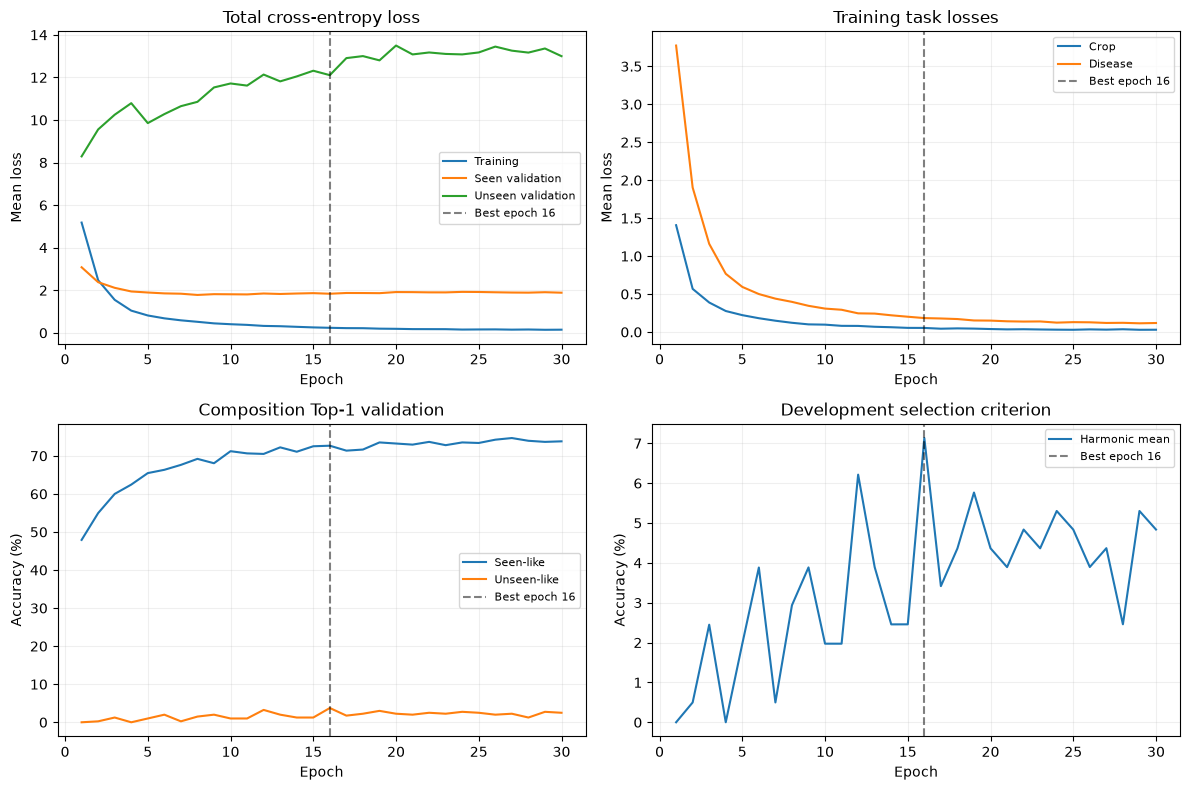

FINISHED exp14_effective_number_disease best epoch 16 saved to c:\AML\ML_Project\Baseline2\outputs\exp14_effective_number_disease
Training closed; starting development-only audit. No second training job will start.


In [8]:
# Confirm the same split hashes and all-pair candidate policy were loaded.
frames, verified_report = validate_development_splits(SPLIT_DIR)
candidates = make_candidates(CONFIG["candidate_mode"], CONFIG["candidate_catalog"])
require_candidate_coverage(candidates, list(frames.values()))
for nm, frame in frames.items():
    if len(frame) != {"train_fit":6905,"val_seen":695,"val_unseen":400}[nm]:
        raise ValueError(f"Unexpected {nm} image count: {len(frame)}")

datasets = {name: DPDDataset(frame, IMAGE_ROOT,
    training_transform(CONFIG) if name=="train_fit" else evaluation_transform(CONFIG["image_size"]))
    for name,frame in frames.items()}
# Decode all metadata-listed development images before spending GPU time.
for dataset in datasets.values():
    for path in dataset.paths:
        with Image.open(path) as im: im.convert("RGB").load()
verified_report["image_paths_checked"] = True
verified_report["image_decoding_checked"] = True
sampler = None
exposure_table = None
if CONFIG["sampling_method"] == "tempered_disease":
    sampler, exposure_table = make_tempered_disease_sampler(
        frames["train_fit"], alpha=CONFIG["sampling_alpha"], seed=CONFIG["seed"])
    print("Exp13: tempered disease sampling alpha=",CONFIG["sampling_alpha"])
else:
    assert CONFIG["sampling_method"] == "natural_shuffle"
    print("Exp14: natural shuffle, no WeightedRandomSampler")
loaders = {name: make_loader(ds, CONFIG,
    shuffle=(name=="train_fit" and sampler is None),
    sampler=(sampler if name=="train_fit" else None)) for name,ds in datasets.items()}
seed_everything(CONFIG["seed"])
example = next(iter(loaders["val_seen"]))
assert tuple(example["image"].shape[1:]) == (3,224,224)
model, history, metrics, experiment_dir = fit_stage1(
    CONFIG,loaders["train_fit"],loaders["val_seen"],loaders["val_unseen"],
    candidates,verified_report,class_mappings,composition_mapping)
if exposure_table is not None:
    exposure_table.to_csv(experiment_dir/"expected_disease_sampling_exposure.csv",index=False)
print("FINISHED", EXPERIMENT_TO_RUN,"best epoch",metrics["epoch"],"saved to",experiment_dir)
del loaders,datasets,example,sampler,model
gc.collect()
plt.close("all")
if DEVICE.type == "cuda": torch.cuda.empty_cache()
print("Training closed; starting development-only audit. No second training job will start.")


## 8. Best-checkpoint development error audit

Predictions and error counts on `val_seen` and `val_unseen` only; `predicted_pair_seen_in_training` is based on the 313 train-fit crop-disease pairs. This reproduces the Exp10 audit protocol, including PyTorch Top-K behavior.

In [9]:
if RUN_AUTO_AUDIT:
    ckpt = EXPERIMENT_DIR / "best_development.pt"
    if not ckpt.is_file():
        raise FileNotFoundError("Exp10 checkpoint missing; cannot audit")
    diagnostic_model, saved = load_checkpoint(ckpt, DEVICE)
    assert saved["stage"] == 1 and saved["config"]["experiment_id"] == EXPERIMENT_TO_RUN
    assert saved["development_split"]["sha256"] == split_report["sha256"], "Split mismatch"
    saved_candidates = torch.as_tensor(saved["candidate_pairs"], dtype=torch.long)
    train_pair_set = set(map(tuple, frames["train_fit"][["crop_id", "disease_id"]].to_numpy().tolist()))
    predictions, audit_summary = {}, []
    for split in ("val_seen", "val_unseen"):
        ds = DPDDataset(frames[split], IMAGE_ROOT, evaluation_transform(CONFIG["image_size"]))
        dl = make_loader(ds, saved["config"], shuffle=False)
        metrics_split, records = evaluate_loader(diagnostic_model, dl, DEVICE, saved_candidates,
                                                   amp=saved["config"]["amp"], collect_predictions=True)
        tab = pd.DataFrame(records)
        assert len(tab) == len(frames[split]) and tab.filename.is_unique
        tab["crop_correct"] = tab.crop_id == tab.predicted_crop_id
        tab["disease_correct"] = tab.disease_id == tab.predicted_disease_id
        tab["crop_only_wrong"] = ~tab.crop_correct & tab.disease_correct
        tab["disease_only_wrong"] = tab.crop_correct & ~tab.disease_correct
        tab["both_wrong"] = ~tab.crop_correct & ~tab.disease_correct
        tab["predicted_pair_seen_in_training"] = [
            (int(c), int(d)) in train_pair_set
            for c,d in zip(tab.predicted_pair_crop_id, tab.predicted_pair_disease_id)]
        if int((tab.crop_correct & tab.disease_correct).sum()) != round(metrics_split["composition_top1"] * len(tab)):
            print("Warning: independent head argmax and composition ranking differ (possible score ties).")
        predictions[split] = tab
        tab.to_csv(EXPERIMENT_DIR / f"{split}_error_predictions.csv", index=False)
        audit_summary.append({"split":split, "n":len(tab),
            "crop_top1":metrics_split["crop_top1"],
            "disease_top1":metrics_split["disease_top1"],
            "composition_top1":metrics_split["composition_top1"],
            "composition_top5":metrics_split["composition_top5"],
            "disease_only_wrong_count":int(tab.disease_only_wrong.sum()),
            "crop_only_wrong_count":int(tab.crop_only_wrong.sum()),
            "both_wrong_count":int(tab.both_wrong.sum()),
            "predicted_pair_seen_in_training_rate":float(tab.predicted_pair_seen_in_training.mean())})
    audit_table = pd.DataFrame(audit_summary)
    audit_table.to_csv(EXPERIMENT_DIR / "task_error_breakdown.csv",index=False)
    display(audit_table)
    print("Saved Experiment predictions + error breakdown")
else:
    print("Auto audit disabled. No evaluation performed.")


,split,n,crop_top1,disease_top1,composition_top1,composition_top5,disease_only_wrong_count,crop_only_wrong_count,both_wrong_count,predicted_pair_seen_in_training_rate
0,val_seen,695,0.890647,0.752518,0.726619,0.880576,114,18,58,0.930935
1,val_unseen,400,0.682500,0.230000,0.037500,0.102500,258,77,50,0.837500


Saved Experiment predictions + error breakdown


## 9. Per-class accuracy and rare-disease evidence

Saves class counts (train-fit only) and per-class seen/unseen performance. Review `spider_mites`, `bacterial_blight`, `angular_leaf_spot`, `late_blight`, and `healthy`, rather than looking only at aggregate HM.

In [10]:
if RUN_AUTO_AUDIT:
    class_counts = {}
    for task in ("crop", "disease", "composition"):
        idcol, namecol = f"{task}_id", f"{task}_name"
        table = (frames["train_fit"].groupby([idcol, namecol], dropna=False)
                 .size().rename("train_images").reset_index()
                 .sort_values(["train_images",namecol], ascending=[True,True]))
        for split in ("val_seen", "val_unseen"):
            counts = frames[split].groupby(idcol).size().rename(f"{split}_images")
            table = table.join(counts,on=idcol)
        table[["val_seen_images","val_unseen_images"]] = table[["val_seen_images","val_unseen_images"]].fillna(0).astype(int)
        table.to_csv(EXPERIMENT_DIR / f"{task}_class_counts.csv",index=False)
        class_counts[task] = table
        print(f"{task}: {len(table)} labels | min {int(table.train_images.min())} | median {table.train_images.median():g} | max {int(table.train_images.max())}")

    MIN_SUPPORT = 5
    per_class = {}
    for split, pred in predictions.items():
        for task in ("crop", "disease"):
            idcol, namecol, predcol = f"{task}_id", f"{task}_name", f"predicted_{task}_id"
            rows = pred.assign(_correct=(pred[idcol]==pred[predcol]).astype(int))
            score = rows.groupby(idcol).agg(n_validation=(idcol,"size"), n_correct=("_correct","sum")).reset_index()
            score["top1_accuracy"] = score.n_correct / score.n_validation
            names = class_counts[task][[idcol,namecol,"train_images"]]
            score=score.merge(names,on=idcol,how="left",validate="one_to_one")
            score["n_wrong"] = score.n_validation - score.n_correct
            errs = rows.loc[rows._correct==0]
            frequent_wrong = (errs.groupby([idcol,predcol]).size().rename("mistake_count")
               .reset_index().sort_values("mistake_count",ascending=False).drop_duplicates(idcol))
            freq_names = dict(zip(names[idcol],names[namecol]))
            frequent_wrong["most_common_wrong_prediction"] = frequent_wrong[predcol].map(freq_names)
            score=score.merge(frequent_wrong[[idcol,"most_common_wrong_prediction","mistake_count"]],
                              on=idcol,how="left")
            score=score.sort_values(["top1_accuracy","n_validation"],ascending=[True,False])
            per_class[(split,task)]=score
            score.to_csv(EXPERIMENT_DIR / f"{split}_{task}_per_class.csv",index=False)
            eligible=score.loc[score.n_validation>=MIN_SUPPORT]
            print(f"\n{split} {task}: {len(eligible)} classes with n >= {MIN_SUPPORT}")
            display(eligible[[namecol,"train_images","n_validation","top1_accuracy","most_common_wrong_prediction"]].head(6))
            display(eligible.sort_values(["top1_accuracy","n_validation"],ascending=[False,False])
                    [[namecol,"train_images","n_validation","top1_accuracy","most_common_wrong_prediction"]].head(6))
else:
    print("Audit disabled")


crop: 55 labels | min 2 | median 38 | max 1007
disease: 175 labels | min 1 | median 8 | max 1417
composition: 313 labels | min 1 | median 6 | max 500

val_seen crop: 27 classes with n >= 5


,crop_name,train_images,n_validation,top1_accuracy,most_common_wrong_prediction
4,bean,27,5,0.400000,corn
6,blackgram,49,5,0.600000,cauliflower
30,mango,100,16,0.687500,apple
5,pepper_bell,56,7,0.714286,tomato
2,banana,93,13,0.769231,coffee
38,pear,94,9,0.777778,apple


,crop_name,train_images,n_validation,top1_accuracy,most_common_wrong_prediction
13,cassava,959,84,1.0,NaN
47,sugarcane,147,15,1.0,NaN
53,wheat,124,13,1.0,NaN
32,olive,107,10,1.0,NaN
37,peanut,114,9,1.0,NaN
35,papaya,57,5,1.0,NaN



val_seen disease: 39 classes with n >= 5


,disease_name,train_images,n_validation,top1_accuracy,most_common_wrong_prediction
48,green_mottle,59,5,0.200000,mosaic
53,spot,83,12,0.416667,streak_virus
106,hispa,67,6,0.500000,downy_mildew
146,septoria_leaf_spot,167,15,0.533333,target_spot
11,marssonina_blotch,75,7,0.571429,rust
15,scab,58,7,0.571429,phytophthora


,disease_name,train_images,n_validation,top1_accuracy,most_common_wrong_prediction
83,streak_virus,201,17,1.000000,NaN
126,diabrotica_speciosa,67,6,1.000000,NaN
3,black_rot,31,5,1.000000,NaN
119,slug,60,5,1.000000,NaN
58,greening,179,16,0.937500,slug
148,yellow_leaf_curl_virus,164,14,0.928571,late_blight


... (2 outputs left out)

,crop_name,train_images,n_validation,top1_accuracy,most_common_wrong_prediction
9,wheat,124,5,1.000000,NaN
8,tomato,1007,70,0.971429,apple
3,cassava,959,117,0.888889,corn
1,bean,27,18,0.833333,blackgram
7,potato,133,70,0.828571,tomato
6,mango,100,18,0.777778,olive



val_unseen disease: 8 classes with n >= 5


,disease_name,train_images,n_validation,top1_accuracy,most_common_wrong_prediction
5,spider_mites,5,70,0.000000,healthy
3,angular_leaf_spot,7,18,0.000000,bean_rust
6,bacterial_leaf_streak,12,5,0.000000,septoria_blotch
4,bacterial_blight,27,117,0.008547,brown_spot
1,monillia_laxa,8,9,0.111111,canker
7,late_blight,103,70,0.271429,early_blight


,disease_name,train_images,n_validation,top1_accuracy,most_common_wrong_prediction
0,healthy,1417,51,0.921569,mosaic
2,powdery_mildew,150,60,0.400000,healthy
7,late_blight,103,70,0.271429,early_blight
1,monillia_laxa,8,9,0.111111,canker
4,bacterial_blight,27,117,0.008547,brown_spot
5,spider_mites,5,70,0.000000,healthy


## 10. Full confusion matrices + readable weak/strong-class summaries

As Exp10, saves separate per-split crop/disease full confusion CSVs and eight small readable summary charts. These are generated automatically; no extra training.

In [11]:
if RUN_AUTO_AUDIT:
    for split, pred in predictions.items():
        for task in ("crop","disease"):
            idcol, namecol, predcol = f"{task}_id", f"{task}_name", f"predicted_{task}_id"
            freq = class_counts[task]
            id_to_name=dict(zip(freq[idcol],freq[namecol]))
            all_ids=sorted(freq[idcol].unique().tolist())
            full = pd.crosstab(pred[idcol],pred[predcol]).reindex(index=all_ids,columns=all_ids,fill_value=0)
            full.index=[f"{i}: {id_to_name[i]}" for i in all_ids]
            full.columns=[f"{i}: {id_to_name[i]}" for i in all_ids]
            full.to_csv(EXPERIMENT_DIR / f"{split}_{task}_full_confusion.csv")
            qualified=per_class[(split,task)].query("n_validation >= @MIN_SUPPORT")
            selections={"weakest":qualified.head(6),
                        "strongest":qualified.sort_values(["top1_accuracy","n_validation"],ascending=[False,False]).head(6)}
            for label,selected in selections.items():
                chosen=selected[idcol].tolist()
                small=pred.loc[pred[idcol].isin(chosen),[idcol,predcol]].copy()
                common=(small.loc[small[idcol]!=small[predcol],predcol]
                        .value_counts().head(5).index.tolist())
                columns=["Correct"]+[f"{int(p)}: {id_to_name.get(int(p),p)}" for p in common]+["Other wrong"]
                counts, labels=[],[]
                for target in chosen:
                    part=small.loc[small[idcol]==target]
                    vals=[int((part[predcol]==target).sum())]
                    vals += [int(((part[predcol]==p)&(part[predcol]!=target)).sum()) for p in common]
                    vals.append(int(((part[predcol]!=target)&(~part[predcol].isin(common))).sum()))
                    assert sum(vals)==len(part), "Confusion row counts do not match support"
                    counts.append(vals)
                    labels.append(f"{id_to_name[target]} (n={len(part)})")
                matrix=pd.DataFrame(counts,index=labels,columns=columns)
                matrix.to_csv(EXPERIMENT_DIR / f"{split}_{task}_{label}_confusion_summary.csv")
                fig,ax=plt.subplots(figsize=(max(8,2+len(columns)*1.2),max(4, len(chosen)*0.6+1)))
                im=ax.imshow(matrix.to_numpy(), aspect="auto")
                ax.set_xticks(np.arange(len(columns)),labels=columns,rotation=45,ha="right",fontsize=8)
                ax.set_yticks(np.arange(len(labels)),labels=labels,fontsize=9)
                for (i,j),value in np.ndenumerate(matrix.to_numpy()):
                    ax.text(j,i,str(value),ha="center",va="center",fontsize=8)
                ax.set_title(f"{EXPERIMENT_TO_RUN} {split} {task} — {label} classes (counts)")
                fig.colorbar(im,ax=ax,label="Images")
                fig.tight_layout()
                fig.savefig(EXPERIMENT_DIR / f"{split}_{task}_{label}_confusion_summary.png",dpi=135,bbox_inches="tight")
                plt.close(fig)
    print("Saved all eight weak/strong confusion summary charts, CSVs and four full confusion matrices")
else:
    print("Audit disabled")


Saved all eight weak/strong confusion summary charts, CSVs and four full confusion matrices


## 11. Consolidated comparison with Exp09/Exp10 and leader summary

Includes unchanged reference development scores from saved Exp09/10 files. Summaries distinguish raw, uncalibrated *trained models* from post-hoc Exp11/12 calibration. New training run is compared under the same 9,625-pair protocol.

In [12]:
records=[]
for name,path in [
    ("Exp09 natural shuffle", EXP09_DIR),
    ("Exp10 tempered alpha=0.25", EXP10_DIR),
    (EXPERIMENT_TO_RUN,EXPERIMENT_DIR),
]:
    mfile=path/"validation_metrics.json"
    if not mfile.is_file():
        print("Reference missing (optional):",mfile)
        continue
    obj=json.loads(mfile.read_text(encoding="utf-8"))
    records.append({"experiment":name,"best_epoch":obj["epoch"],
        "seen_comp":obj["seen"]["composition_top1"],
        "unseen_comp":obj["unseen"]["composition_top1"],
        "HM":obj["composition_harmonic_mean"],
        "unseen_crop":obj["unseen"]["crop_top1"],
        "unseen_disease":obj["unseen"]["disease_top1"],
        "unseen_correct_of_400":round(obj["unseen"]["composition_top1"]*400)})
comparison = pd.DataFrame(records)
comparison.to_csv(EXPERIMENT_DIR/"exp09_exp10_new_development_comparison.csv",index=False)
display(comparison)

base_name="Exp09 natural shuffle"
if base_name in comparison.experiment.tolist():
    row= comparison.loc[comparison.experiment==EXPERIMENT_TO_RUN].iloc[0]
    base=comparison.loc[comparison.experiment==base_name].iloc[0]
    diffs={key:(float(row[key])-float(base[key]))*100 for key in
           ["seen_comp","unseen_comp","HM","unseen_crop","unseen_disease"]}
else:
    diffs={}
train_unseen=per_class[("val_unseen","disease")]
rare=train_unseen.loc[train_unseen.n_validation>=5].sort_values("top1_accuracy").head(8)
view_cols=["disease_name","train_images","n_validation","top1_accuracy","most_common_wrong_prediction"]
msg=[f"# {EXPERIMENT_TO_RUN} — Development-only training results", "",
     f"- Intervention: {CONFIG['changed_parameter']}",
     "- All other key Exp09 settings fixed: ResNet50_V2, batch16, size224, seed42, LR 1e-5/1e-3, AdamW, weight decay 1e-3, 9,625 candidate pairs.",
     f"- Best epoch: {metrics['epoch']} (selected on development composition HM)",
     f"- Seen composition: {metrics['seen']['composition_top1']:.2%}",
     f"- Unseen composition: {metrics['unseen']['composition_top1']:.2%}",
     f"- HM: {metrics['composition_harmonic_mean']:.2%}",
     f"- Unseen crop: {metrics['unseen']['crop_top1']:.2%}; unseen disease: {metrics['unseen']['disease_top1']:.2%}",
     f"- Unseen correct: {round(metrics['unseen']['composition_top1']*400)}/400", ""]
if diffs:
    msg.append("## Difference from Exp09 (percentage points)")
    for k,v in diffs.items(): msg.append(f"- {k}: {v:+.2f} pp")
    msg.append("")
msg += ["## Weak unseen disease classes (>=5 validation images)",
        rare[view_cols].to_markdown(index=False),"",
        "## Protocol and limits",
        "- No Stage 2, official test, calibration or re-training of reference checkpoints.",
        "- Single seed (42); development set used many times. These are exploratory comparisons, not independent test scores.",
        "- Do not interpret changes as statistically robust without multi-seed / independent evaluation.",
        "- Exp13 tests alpha 0.5 vs natural / alpha 0.25; Exp14 separately tests CB disease loss while restoring natural shuffle.",
        "- Original official test is not accessed or used for selection."]
(EXPERIMENT_DIR/"leader_summary.md").write_text("\n".join(msg)+"\n",encoding="utf-8")
print("Saved comparison and leader_summary.md:",EXPERIMENT_DIR)
# Release GPU audit model too, after all its outputs were saved.
if "diagnostic_model" in globals():
    del diagnostic_model
    gc.collect()
    torch.cuda.empty_cache()


,experiment,best_epoch,seen_comp,unseen_comp,HM,unseen_crop,unseen_disease,unseen_correct_of_400
0,Exp09 natural shuffle,12,0.729496,0.0400,0.075841,0.7050,0.2200,16
1,Exp10 tempered alpha=0.25,13,0.732374,0.0400,0.075857,0.6925,0.2325,16
2,exp14_effective_number_disease,16,0.726619,0.0375,0.071319,0.6825,0.2300,15


Saved comparison and leader_summary.md: c:\AML\ML_Project\Baseline2\outputs\exp14_effective_number_disease


## 12. How to run the other experiment later (not automatic)

If Exp13 has completed and the team wants to test the effective-number disease loss, go back to Section 1 and change:

```python
EXPERIMENT_TO_RUN = "exp14_effective_number_disease"
```

Then **Restart Kernel → Run All**. This creates a *separate* `outputs/exp14_effective_number_disease/` folder and never overwrites `outputs/exp13_tempered_alpha05/`.

Do **not** increase GPU workers/batch size merely to accelerate training; on your 6 GiB RTX4050 and 16 GB RAM laptop, monitor `nvidia-smi`, temperatures, RAM and ventilation. If code fails, inspect the error and resume safely rather than rerunning blindly. The beta=0.99 choice is a first controlled trial, not an optimized hyperparameter.

In [13]:
%pip install tabulate

Note: you may need to restart the kernel to use updated packages.
